# Calibración de la eficiencia del tubo 1

## Procedimiento

La medición se hizo el **1/10/2026, de 17:35 a 17:55** (20 min), con los tres módulos (centellador + PMT) apilados y
conectados al DRS4 así:

| canal DRS4 | tubo |
|---|---|
| CH1 | tubo 2 |
| CH2 | **tubo 1** (el que se calibra) |
| CH3 | tubo 3 |

- El **trigger** del DRS4 es CH1 (tubo 2), por flanco negativo con umbral $-100$ mV.
- `drs_exam` guarda **solo** los eventos seleccionados: además del trigger, otro de los tubos de referencia
  tiene que tener un pulso por debajo de $-100$ mV en la ventana de muestras 100–150 (166–249 ns). Así cada evento
  guardado es un muón que atravesó los dos tubos de referencia (2 y 3).
- La **eficiencia del tubo 1** es la fracción de esos eventos en los que el tubo 1 también da pulso:

$$\varepsilon_1 = \frac{N(\text{2 y 3 y 1})}{N(\text{2 y 3})} = \frac{k}{N}.$$

Como el tubo 1 no entra en la selección, la medición no está sesgada por él: se cuenta qué fracción de los muones
que ya se sabe que pasaron por el apilado ve el tubo 1.

Los datos son la corrida `run_20261001_161000` (empezó a las 16:10 y siguió hasta las 17:55). Acá se usan solo los
eventos con marca de tiempo en $[17{:}35,\ 17{:}55)$.

In [2]:
from pathlib import Path
from datetime import datetime
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb
from IPython.display import display

DIR = Path('../grupo_7_jueves/medidas')
RUN = 'run_20261001_161000'
T_INI = datetime(2026, 10, 1, 17, 35)
T_FIN = datetime(2026, 10, 1, 17, 55)

THR = 100            # [mV] umbral de pulso, el mismo que el trigger y la selección de drs_exam
VENTANA = (100, 150) # muestras donde se busca el pulso (igual que drs_exam)

TUBO = {1: 'CH1 · tubo 2', 2: 'CH2 · tubo 1', 3: 'CH3 · tubo 3'}
COLOR = {1: '#2a78d6', 2: '#eb6834', 3: '#1baf7a'}

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 11, 'legend.frameon': False,
    'axes.grid': True, 'grid.color': '#e4e3dd', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110,
})

## 1. Lectura

Cada archivo `*_selected.txt` tiene eventos con encabezado `Event #n  ts=...` y 1024 filas `t u1 u2 u3`.

In [3]:
RE_EVENTO = re.compile(rb'^Event #(\d+)\s+ts=(\S+ \S+)[^\n]*\n[^\n]*\n', re.M)


def leer(ruta):
    datos = ruta.read_bytes()
    ms = list(RE_EVENTO.finditer(datos))
    for k, m in enumerate(ms):
        fin = ms[k + 1].start() if k + 1 < len(ms) else len(datos)
        onda = np.array(datos[m.end():fin].split(), dtype=float).reshape(-1, 4)
        ts = datetime.strptime(m.group(2).decode(), '%Y-%m-%d %H:%M:%S.%f')
        yield int(m.group(1)), ts, onda


todos = [e for ruta in sorted(DIR.glob(f'{RUN}_idx*_selected.txt'), key=lambda p: int(re.search(r'idx(\d+)', p.name)[1]))
         for e in leer(ruta)]
ts_todos = pd.Series([e[1] for e in todos])
en_ventana = [e for e in todos if T_INI <= e[1] < T_FIN]

ev = pd.DataFrame({'evento': [e[0] for e in en_ventana], 'ts': [e[1] for e in en_ventana]})
ONDAS = np.stack([e[2] for e in en_ventana])          # (N, 1024, 4): t, u1, u2, u3
T = ONDAS[0, :, 0]
print(f'{len(todos)} eventos en toda la corrida, {len(ev)} entre {T_INI:%H:%M} y {T_FIN:%H:%M}')
print(f'ventana de búsqueda: t = {T[VENTANA[0]]:.0f}–{T[VENTANA[1]]:.0f} ns')

1046 eventos en toda la corrida, 205 entre 17:35 y 17:55
ventana de búsqueda: t = 166–249 ns


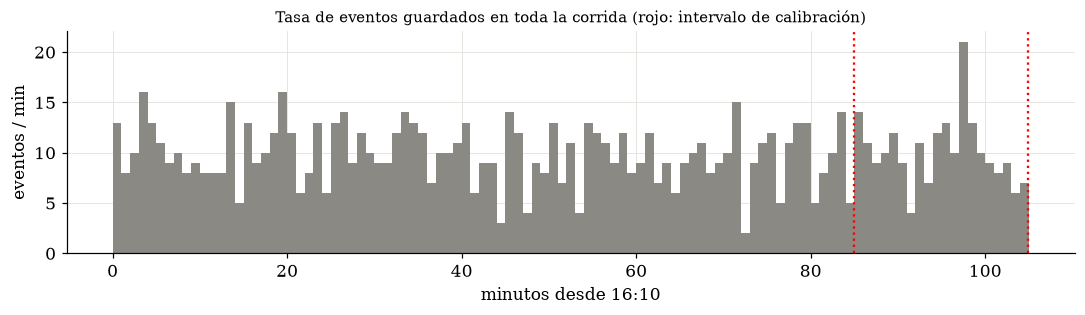

In [4]:
fig, ax = plt.subplots(figsize=(10, 3))
minutos = (ts_todos - ts_todos.iloc[0]).dt.total_seconds() / 60
bins = np.arange(0, minutos.max() + 1, 1)
ax.hist(minutos, bins=bins, color='#8a8984')
for t in (T_INI, T_FIN):
    ax.axvline((t - ts_todos.iloc[0]).total_seconds() / 60, color='red', ls=':')
ax.set_xlabel(f'minutos desde {ts_todos.iloc[0]:%H:%M}')
ax.set_ylabel('eventos / min')
ax.set_title('Tasa de eventos guardados en toda la corrida (rojo: intervalo de calibración)', fontsize=10)
fig.tight_layout()
plt.show()

## 2. Amplitudes y limpieza

Para cada canal se calcula la línea de base (mediana de las primeras 80 muestras, antes del pulso), el mínimo en
la ventana y el máximo de toda la forma de onda.

Hay ráfagas de **interferencia** (eventos separados por ~20 ms, a las 17:47–17:48) en las que CH1 y CH2 oscilan y
saturan a $\pm 500$ mV y la base de CH3 se corre ~$-230$ mV. No son muones: un muón da un pulso solo negativo.

Criterio de limpieza: se descartan los eventos en los que **algún canal sube de $+100$ mV** (el nivel del trigger,
pero hacia arriba), igual que en `filtrado_muones.ipynb`. Las dos poblaciones están muy separadas (en los muones el
máximo positivo no pasa de ~60 mV; la interferencia llega a +500 mV), así que el resultado no depende del valor
exacto del corte.

In [5]:
u = ONDAS[:, :, 1:]                                    # (N, 1024, 3)
base = np.median(u[:, :80, :], axis=1)
vmin = u[:, VENTANA[0]:VENTANA[1], :].min(axis=1)       # crudo, como lo ve el trigger / drs_exam
vmax = u.max(axis=1)
for c in (1, 2, 3):
    ev[f'base{c}'] = base[:, c - 1]
    ev[f'vmin{c}'] = vmin[:, c - 1]
    ev[f'amp{c}'] = vmin[:, c - 1] - base[:, c - 1]     # respecto de la base
    ev[f'vmax{c}'] = vmax[:, c - 1]

ev['interferencia'] = (ev[[f'vmax{c}' for c in (1, 2, 3)]] > THR).any(axis=1)
limpio = ev[~ev['interferencia']].copy()
print(f'descartados por interferencia: {ev["interferencia"].sum()}  ->  quedan {len(limpio)} eventos')
print('máximo positivo de los eventos limpios por canal [mV]:', limpio[[f'vmax{c}' for c in (1, 2, 3)]].max().values)
display(ev.loc[ev['interferencia'], ['evento', 'ts', 'base3', 'vmin1', 'vmin2', 'vmax1', 'vmax2']].head(6))

descartados por interferencia: 20  ->  quedan 185 eventos
máximo positivo de los eventos limpios por canal [mV]: [59.5 54.2 51.4]


,evento,ts,base3,vmin1,vmin2,vmax1,vmax2
119,19615,2026-10-01 17:47:04.973,-101.05,-499.9,-499.9,500.0,500.0
120,19618,2026-10-01 17:47:04.993,-236.30,-499.9,-499.9,500.0,500.0
128,20011,2026-10-01 17:47:46.852,-239.45,-499.9,-499.9,500.0,500.0
129,20013,2026-10-01 17:47:46.872,-246.60,-499.9,-499.9,500.0,500.0
130,20015,2026-10-01 17:47:46.892,-232.50,-499.9,-499.9,500.0,500.0
131,20018,2026-10-01 17:47:46.912,-206.15,-499.9,-499.9,500.0,500.0


### Ejemplo: muón e interferencia

Figura con el estilo de `ESTILO_FIGURAS.md`. Se guardan en `muones/figuras/evento_muon.{pdf,png}` y `muones/figuras/evento_interferencia.{pdf,png}`.

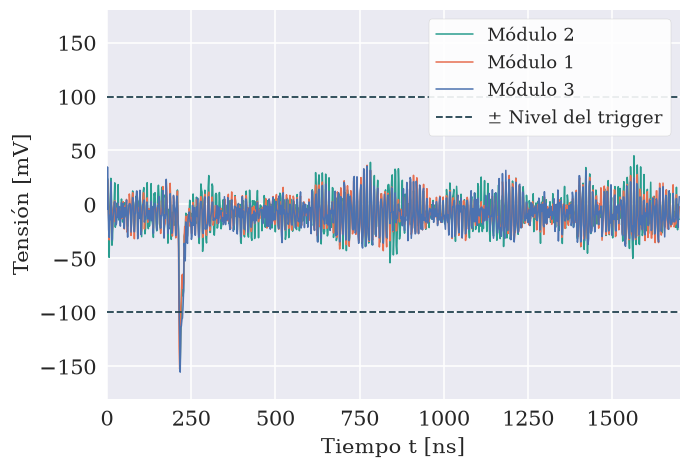

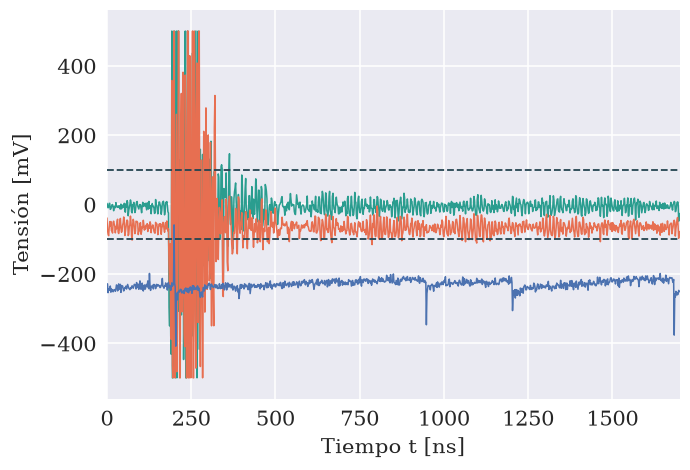

(a) evento 19431 (17:44:46), (b) evento 20011 (17:47:46)


In [12]:
DIR_FIG = Path('../figuras')
COLOR_FIG = {1: '#2A9D8F', 2: '#E76F51', 3: '#4C72B0'}     # CH1 · tubo 2, CH2 · tubo 1, CH3 · tubo 3
NOMBRE_FIG = {1: 'Módulo 2', 2: 'Módulo 1', 3: 'Módulo 3'}

# muón típico: evento limpio con la amplitud del tubo 1 más cercana a la mediana
i_muon = (limpio['amp2'] - limpio['amp2'].median()).abs().idxmin()
i_ruido = ev.index[ev['evento'] == 20011][0]                # una de las ráfagas de 17:47

fs = 14
estilo = {'font.family': 'serif', 'font.size': fs, 'axes.labelsize': fs, 'xtick.labelsize': fs,
          'ytick.labelsize': fs, 'legend.fontsize': fs, 'mathtext.default': 'regular',
          'mathtext.fontset': 'cm', 'legend.frameon': True}
with plt.style.context('seaborn-v0_8'), plt.rc_context(estilo):
    for i, archivo, con_leyenda, ylim in [(i_muon, 'evento_muon', True, (-180, 180)), (i_ruido, 'evento_interferencia', False, (-560, 560))]:
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        for c in (1, 2, 3):
            ax.plot(T, ONDAS[i, :, c], color=COLOR_FIG[c], lw=1, label=NOMBRE_FIG[c])
        ax.axhline(-THR, color='#264653', ls='--', lw=1.2, label=f'$\\pm$ Nivel del trigger')
        ax.axhline(+THR, color='#264653', ls='--', lw=1.2)
        ax.set_xlim(0, 1700)
        ax.set_xticks(np.arange(0, 1701, 250))
        ax.set_ylim(*ylim)
        ax.set_xlabel('Tiempo $t$ [ns]')
        ax.set_ylabel('Tensión [mV]')
        if con_leyenda:
            ax.legend(loc='upper right', fontsize=12, facecolor='white', framealpha=0.9)
        fig.tight_layout()
        fig.savefig(DIR_FIG / f'{archivo}.pdf', bbox_inches='tight')
        fig.savefig(DIR_FIG / f'{archivo}.png', bbox_inches='tight', dpi=300)
        plt.show()

print(f'(a) evento {ev.loc[i_muon, "evento"]} ({ev.loc[i_muon, "ts"]:%H:%M:%S}), '
      f'(b) evento {ev.loc[i_ruido, "evento"]} ({ev.loc[i_ruido, "ts"]:%H:%M:%S})')

**Pie de figura.** Formas de onda de los tres tubos para dos eventos guardados durante la calibración del tubo 1.
(a) Muón típico: un pulso negativo de ~10 ns, simultáneo en los tres tubos.
(b) Evento de interferencia (17:47:46): los tubos 1 y 2 oscilan y saturan a $\pm 500$ mV durante más de 100 ns y la
línea de base del tubo 3 está corrida a ~$-230$ mV. Las líneas a trazos marcan $\pm 100$ mV: el umbral de
pulso y el corte de limpieza (se descartan los eventos en los que algún canal sube de $+100$ mV).

### ¿Qué canales están en la selección?

Si un canal formó parte del trigger/selección, **todos** los eventos tienen ahí un mínimo por debajo de $-100$ mV.
CH1 y CH3 cumplen eso en el 100 % de los eventos (su distribución está cortada en $-100$ mV); CH2 no: tiene eventos
por encima del umbral. Esto confirma que la coincidencia de referencia fue **tubo 2 (CH1) y tubo 3 (CH3)**, y que
el tubo 1 (CH2) quedó libre, que es lo que hace falta para medir su eficiencia.

(El `drs_exam.cpp` commiteado ese día pedía el pulso en CH2; los datos muestran que el binario que corrió en este
intervalo pedía CH3.)

fracción de eventos con mínimo < -THR en la ventana:
  CH1 · tubo 2: 1.000   máx. de vmin = -115.5 mV
  CH2 · tubo 1: 0.989   máx. de vmin = -57.3 mV
  CH3 · tubo 3: 1.000   máx. de vmin = -100.3 mV


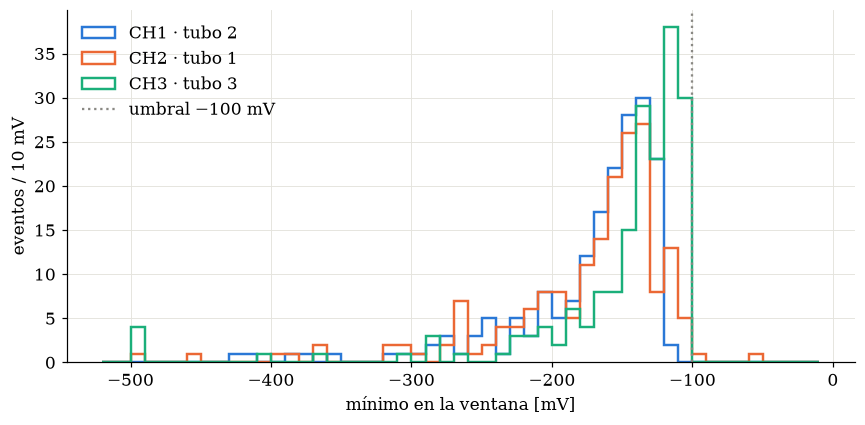

In [7]:
print('fracción de eventos con mínimo < -THR en la ventana:')
for c in (1, 2, 3):
    print(f'  {TUBO[c]}: {(limpio[f"vmin{c}"] < -THR).mean():.3f}   máx. de vmin = {limpio[f"vmin{c}"].max():.1f} mV')

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(-520, 0, 10)
for c in (1, 2, 3):
    ax.hist(limpio[f'vmin{c}'], bins=bins, histtype='step', lw=1.6, color=COLOR[c], label=TUBO[c])
ax.axvline(-THR, color='#8a8984', ls=':', label=f'umbral −{THR} mV')
ax.set_xlabel('mínimo en la ventana [mV]')
ax.set_ylabel('eventos / 10 mV')
ax.legend()
fig.tight_layout()
plt.show()

## 3. Eficiencia

Se cuenta un pulso en el tubo 1 si el mínimo de CH2 en la ventana baja de $-100$ mV (mismo criterio que la
selección de `drs_exam`). Con $k$ éxitos en $N$ ensayos, la incerteza sale de la distribución binomial. Como
$\varepsilon$ está cerca de 1, la aproximación $\sqrt{\varepsilon(1-\varepsilon)/N}$ subestima el error, así que se da
además el intervalo exacto de Clopper–Pearson al 68 %.

In [8]:
def cdf_binomial(k, n, p):
    return sum(comb(n, j) * p**j * (1 - p)**(n - j) for j in range(k + 1))


def biseccion(f, lo=0.0, hi=1.0, it=60):
    # raíz de f creciente en [lo, hi]
    for _ in range(it):
        m = (lo + hi) / 2
        lo, hi = (m, hi) if f(m) < 0 else (lo, m)
    return (lo + hi) / 2


def clopper_pearson(k, n, cl=0.6827):
    # intervalo exacto: P(X >= k | p_inf) = a  y  P(X <= k | p_sup) = a
    a = (1 - cl) / 2
    lo = biseccion(lambda p: (1 - cdf_binomial(k - 1, n, p)) - a) if k > 0 else 0.0
    hi = biseccion(lambda p: a - cdf_binomial(k, n, p)) if k < n else 1.0
    return lo, hi


def eficiencia(pasa):
    n, k = len(pasa), int(pasa.sum())
    e = k / n
    lo, hi = clopper_pearson(k, n)
    return dict(k=k, N=n, eficiencia=e, sigma_binomial=np.sqrt(e * (1 - e) / n), CP68_inf=lo, CP68_sup=hi)


res = pd.DataFrame({
    'crudo (como drs_exam)': eficiencia(limpio['vmin2'] < -THR),
    'respecto de la base': eficiencia(limpio['amp2'] < -THR),
}).T
res[['k', 'N']] = res[['k', 'N']].astype(int)
display(res.round(3))
r = res.iloc[0]
print(f'ε(tubo 1, umbral {THR} mV) = {r.eficiencia:.3f}  (+{r.CP68_sup - r.eficiencia:.3f} / -{r.eficiencia - r.CP68_inf:.3f})')

,k,N,eficiencia,sigma_binomial,CP68_inf,CP68_sup
crudo (como drs_exam),183,185,0.989,0.008,0.975,0.996
respecto de la base,180,185,0.973,0.012,0.955,0.985


ε(tubo 1, umbral 100 mV) = 0.989  (+0.007 / -0.014)


### Dependencia con el umbral

La amplitud del tubo 1 está centrada en ~150 mV, no muy lejos del umbral de 100 mV, así que la eficiencia
depende bastante del umbral que se elija. La curva sirve para elegir el umbral en las mediciones siguientes
(en la meseta la eficiencia es ~1 y la medición es insensible a fluctuaciones de ganancia).

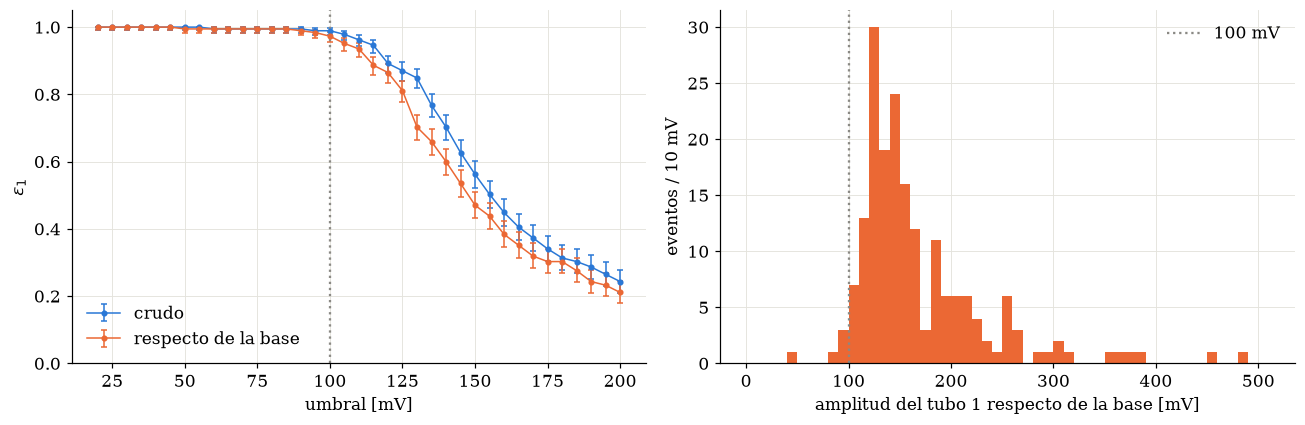

criterio,crudo,respecto de la base
umbral,,
30,1.000,1.000
50,1.000,0.995
70,0.995,0.995
100,0.989,0.973
120,0.892,0.865
150,0.562,0.470


In [9]:
umbrales = np.arange(20, 205, 5)
filas = []
for thr in umbrales:
    for nombre, col in [('crudo', 'vmin2'), ('respecto de la base', 'amp2')]:
        d = eficiencia(limpio[col] < -thr)
        filas.append(dict(umbral=thr, criterio=nombre, **d))
curva = pd.DataFrame(filas)

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
for (nombre, g), color in zip(curva.groupby('criterio'), ['#2a78d6', '#eb6834']):
    a.errorbar(g['umbral'], g['eficiencia'], yerr=[g['eficiencia'] - g['CP68_inf'], g['CP68_sup'] - g['eficiencia']],
               fmt='o-', ms=3, lw=1, capsize=2, color=color, label=nombre)
a.axvline(THR, color='#8a8984', ls=':')
a.set_xlabel('umbral [mV]')
a.set_ylabel(r'$\varepsilon_1$')
a.set_ylim(0, 1.05)
a.legend()

b.hist(-limpio['amp2'], bins=np.arange(0, 520, 10), color=COLOR[2])
b.axvline(THR, color='#8a8984', ls=':', label=f'{THR} mV')
b.set_xlabel('amplitud del tubo 1 respecto de la base [mV]')
b.set_ylabel('eventos / 10 mV')
b.legend()
fig.tight_layout()
plt.show()

display(curva[curva['umbral'].isin([30, 50, 70, 100, 120, 150])].pivot(index='umbral', columns='criterio', values='eficiencia').round(3))

## 4. Eventos en los que el tubo 1 no dispara

Formas de onda de los eventos limpios en los que CH2 no baja de $-100$ mV (respecto de la base).

5 eventos


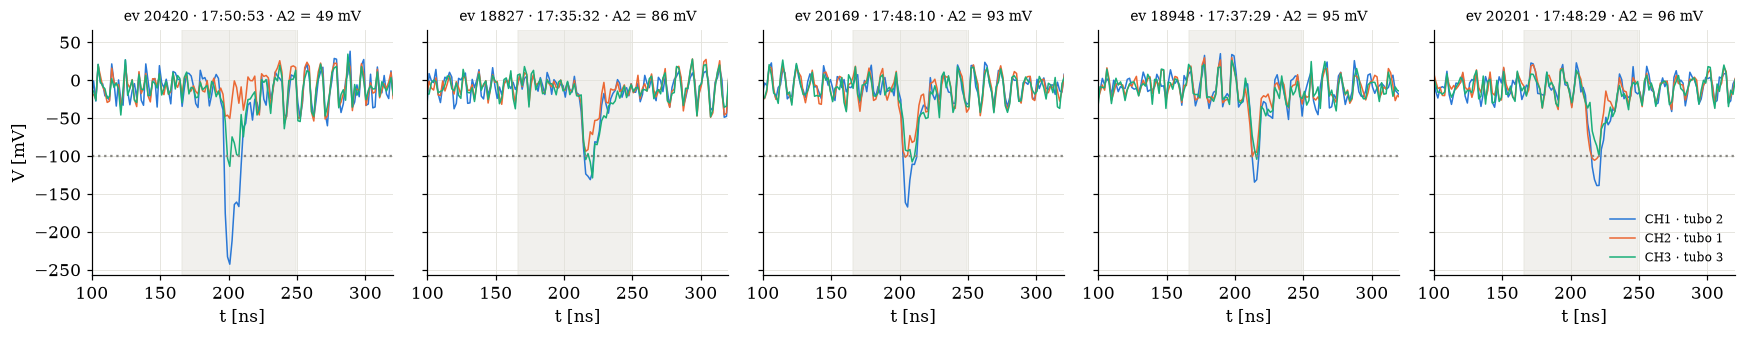

In [10]:
fallan = limpio[limpio['amp2'] >= -THR].sort_values('amp2', ascending=False)
print(f'{len(fallan)} eventos')
n = min(len(fallan), 6)
fig, axs = plt.subplots(1, n, figsize=(3.2 * n, 3.2), sharey=True, squeeze=False)
for ax, (i, f) in zip(axs[0], fallan.head(n).iterrows()):
    for c in (1, 2, 3):
        ax.plot(T, ONDAS[i, :, c], color=COLOR[c], lw=1, label=TUBO[c])
    ax.axhline(-THR, color='#8a8984', ls=':')
    ax.axvspan(T[VENTANA[0]], T[VENTANA[1]], color='#e4e3dd', alpha=0.5)
    ax.set_xlim(100, 320)
    ax.set_title(f'ev {f.evento} · {f.ts:%H:%M:%S} · A2 = {-f.amp2:.0f} mV', fontsize=9)
    ax.set_xlabel('t [ns]')
axs[0, 0].set_ylabel('V [mV]')
axs[0, -1].legend(fontsize=8, loc='lower right')
fig.tight_layout()
plt.show()

## 5. Resultado

Ver la tabla de la sección 3. Con el mismo umbral que usa la adquisición ($-100$ mV, sin restar la base),
la eficiencia del tubo 1 es la de la fila *crudo*; restando la base el resultado baja un poco porque la base de CH2
está en ~$-7$ mV.

Comentarios:
- **Las fallas son de umbral, no de luz:** en los eventos donde el tubo 1 "no dispara" (sección 4) hay un pulso
  claro en CH2, simultáneo con los de CH1 y CH3, pero con amplitud de 50–96 mV, apenas por debajo del umbral. El
  tubo ve prácticamente todos los muones; lo que se pierde es la cola baja del espectro de amplitudes.
- **Estadística:** con $N \approx 185$ y casi todos éxitos, la incerteza es de ~1 % y está dominada por los pocos
  eventos que fallan. Para bajarla hace falta medir más tiempo.
- **Umbral:** la eficiencia cae rápido por encima de 120 mV (la amplitud típica del tubo 1 es ~150 mV). Para que la
  eficiencia sea ~1 conviene trabajar con umbrales de 50–70 mV en este tubo, o subirle la tensión al PMT.
- **Coincidencias accidentales:** a ~10 eventos/min y con una ventana de ~80 ns, la probabilidad de que el tubo 1
  dispare por ruido dentro de la ventana es despreciable, así que no infla la eficiencia.
- **Geometría:** la eficiencia medida incluye la aceptancia. Si algún muón pasa por los tubos 2 y 3 pero no por el 1
  (por ejemplo, si el área del tubo 1 no cubre la de los otros dos), cuenta como falla. Con los módulos alineados
  este efecto es chico.